Let's implement a 3D EKF. 

## Rotations
In 2D, roll and pitch do not exist. When going into 3D, using Euler angles as the attitude state represents two major problems:
- **The Singularity (Gimbal Lock)**
- **Aggressive Non-Linearity**

We will first understand the ways to represent the attitude of a body with respect to a world frame and how this attitude evolves with time. We will also explain the issues with the Euler angles by implementing an EKF with it.



The EKF works by linearizing the physics (the Taylor expansion). Euler angles are brutally non-linear, requiring heavy trigonometry and suffering from wrap-around issues at $360^\circ$. Because the functions curve so sharply, the linear approximation (the Jacobian $A$) loses accuracy very quickly if the vehicle undergoes high-dynamic maneuvers between time steps.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [17]:
def compute_matrices(x: np.ndarray, u: np.ndarray):
    """
    Computes the rotation matrix, rate mapping matrix, and specific Jacobian blocks 
    required for the state extrapolation and for the continuous-time system matrix A

    x : np.ndarray
        The 15-element system state vector:
        [p_x, p_y, p_z, v_x, v_y, v_z, phi, theta, psi, b_ax, b_ay, b_az, b_gx, b_gy, b_gz]
    u : np.ndarray
        The 6-element IMU measurement vector:
        [a_x, a_y, a_z, w_x, w_y, w_z] (measured accelerations and angular velocities)

    R_W : np.ndarray
        (3, 3) Rotation matrix from body frame to world frame.
    B : np.ndarray
        (3, 3) Mapping matrix from body angular rates to Euler angle rates (phi, theta, psi).
    M : np.ndarray
        (3, 3) Jacobian block of the Euler angle rates with respect to the Euler angles.
    V_Theta : np.ndarray
        (3, 3) Jacobian block of the rotated unbiased accelerations with respect to the Euler angles.
    """
    phi, theta, psi = x[6:9]  # (roll, pitch, yaw)

    b_a = x[9:12]   # Accelerometer bias
    b_g = x[12:15]  # Gyroscope bias
    a_m = u[0:3]    # [ax, ay, az] Measured acceleration
    w_m = u[3:6]    # [wx, wy, wz] Measured angular velocity

    a_unb = a_m - b_a
    w_unb = w_m - b_g
    wb_x, wb_y, wb_z = w_unb  # Unpack for the M matrix

    c_phi, s_phi = np.cos(phi), np.sin(phi)
    c_theta, s_theta = np.cos(theta), np.sin(theta)
    c_psi, s_psi = np.cos(psi), np.sin(psi)
    
    t_theta = s_theta / c_theta
    sec2_theta = 1.0 / (c_theta ** 2)

    # World Rotation Matrix
    R_W = np.array([
        [
            c_psi * c_theta,
            c_psi * s_theta * s_phi - s_psi * c_phi,
            c_psi * s_theta * c_phi + s_psi * s_phi,
        ],
        [
            s_psi * c_theta,
            s_psi * s_theta * s_phi + c_psi * c_phi,
            s_psi * s_theta * c_phi - c_psi * s_phi,
        ],
        [-s_theta, c_theta * s_phi, c_theta * c_phi],
    ])
    
    # Body rates to Euler rates mapping (B)
    B = np.array([
        [1, s_phi * t_theta, c_phi * t_theta],
        [0, c_phi, -s_phi],
        [0, s_phi / c_theta, c_phi / c_theta]
    ])
    
    # Partial derivatives of attitude rates w.r.t Euler angles (M)
    M = np.array([
        [(wb_y * c_phi * t_theta - wb_z * s_phi * t_theta), (wb_y * s_phi * sec2_theta + wb_z * c_phi * sec2_theta), 0],
        [(-wb_y * s_phi - wb_z * c_phi),                    0,                                                      0],
        [(wb_y * c_phi / c_theta - wb_z * s_phi / c_theta), (wb_y * s_phi * s_theta * sec2_theta + wb_z * c_phi * s_theta * sec2_theta), 0]
    ])
    
    # Base rotation matrices for chain rule
    Rx = np.array([[1, 0, 0], [0, c_phi, -s_phi], [0, s_phi, c_phi]])
    Ry = np.array([[c_theta, 0, s_theta], [0, 1, 0], [-s_theta, 0, c_theta]])
    Rz = np.array([[c_psi, -s_psi, 0], [s_psi, c_psi, 0], [0, 0, 1]])
    
    # Partial derivatives of base rotation matrices w.r.t their respective angles
    dRx_dphi   = np.array([[0, 0, 0], [0, -s_phi, -c_phi], [0, c_phi, -s_phi]])
    dRy_dtheta = np.array([[-s_theta, 0, c_theta], [0, 0, 0], [-c_theta, 0, -s_theta]])
    dRz_dpsi   = np.array([[-s_psi, -c_psi, 0], [c_psi, -s_psi, 0], [0, 0, 0]])
    
    # Chain rule for the combined rotation matrix R_w w.r.t each angle
    dR_dphi   = Rz @ Ry @ dRx_dphi
    dR_dtheta = Rz @ dRy_dtheta @ Rx
    dR_dpsi   = dRz_dpsi @ Ry @ Rx
    
    # Multiply by the unbiased acceleration vector to get the column vectors of V_Theta
    V_Theta = np.column_stack((
        dR_dphi @ a_unb,
        dR_dtheta @ a_unb,
        dR_dpsi @ a_unb
    ))
    
    return R_W, B, M, V_Theta

In [60]:
def _integrate_kinematics(x: np.ndarray, u: np.ndarray, dt: np.float64, R_W: np.ndarray, B: np.ndarray):
    p = x[0:3]  # [px, py, pz]
    v = x[3:6]  # [vx, vy, vz]
    attitude = x[6:9]  # [phi, theta, psi] (roll, pitch, yaw) 
    b_a = x[9:12]   # Accelerometer bias
    b_g = x[12:15]  # Gyroscope bias

    a_m = u[0:3]  # [ax, ay, az] Measured acceleration
    w_m = u[3:6]  # [wx, wy, wz] Measured angular velocity

    # rotate unbiased acceleration to world frame
    a_W = R_W @ (a_m - b_a)
    g_W = np.array([0.0, 0.0, -9.81])
    v_delta = (a_W + g_W)

    # integrate kinematics
    v_k = v + v_delta * dt
    p_k = p + v * dt + .5 * v_delta * dt**2
    attitude_k = attitude + B @ (w_m - b_g) * dt

    return np.concat([p_k, v_k, attitude_k, b_a, b_g])

In [61]:
def compute_continuous_jacobian(R_w, V_Theta, M, B):
    """
    Constructs the 15x15 continuous-time Jacobian matrix A
    """

    I = np.eye(3)
    Z = np.zeros((3, 3))
    
    A = np.block([
        [Z, I, Z,       Z,    Z],
        [Z, Z, V_Theta, -R_w, Z],
        [Z, Z, M,       Z,    -B],
        [Z, Z, Z,       Z,    Z],
        [Z, Z, Z,       Z,    Z]
    ])
    
    return A

In [62]:
class EKF_3D:
    def __init__(self, 
            # initial state
            px0=0.0, py0=0.0, pz0=0.0,
            vx0=0.0, vy0=0.0, vz0=0.0,
            phi0=0.0, theta0=0.0, psi0=0.0,
            bax0=0.0, bay0=0.0, baz0=0.0,
            bgx0=0.0, bgy0=0.0, bgz0=0.0,

            # initial uncertainty
            sigma_p0=0.5,
            sigma_v0=0.5,
            sigma_att0=0.1,
            sigma_ba0=0.1,
            sigma_bg0=0.1,

            # control noise
            sigma_a=1e-3, sigma_g=1e-4,
            sigma_ba=1e-4, sigma_bg=1e-5,

            # measurement noise stdev
            sigma_px=3., sigma_py=3., sigma_pz=5,
            sigma_vx=.5, sigma_vy=.5, sigma_vz=.5,

            dt=np.float64(0.01)
        ):
        self.dt = dt

        self.x = np.array([
            px0, py0, pz0, 
            vx0, vy0, vz0, 
            phi0, theta0, psi0, 
            bax0, bay0, baz0, 
            bgx0, bgy0, bgz0
        ])

        self.P = np.diag([
            sigma_p0**2, sigma_p0**2, sigma_p0**2,
            sigma_v0**2, sigma_v0**2, sigma_v0**2,
            sigma_att0**2, sigma_att0**2, sigma_att0**2,
            sigma_ba0**2, sigma_ba0**2, sigma_ba0**2,
            sigma_bg0**2, sigma_bg0**2, sigma_bg0**2
        ])

        I = np.identity(3)
        Z = np.zeros((3, 3))
        
        self.sigma_g = sigma_g
        Q_p = np.zeros((3, 3))
        Q_v = (sigma_a**2 * dt) * I
        Q_ba = (sigma_ba**2 * dt) * I
        Q_bg = (sigma_bg**2 * dt) * I
        self.Q = np.block([
            [Q_p, Z,   Z, Z,    Z],
            [Z,   Q_v, Z, Z,    Z],
            [Z,   Z,   Z, Z,    Z],
            [Z,   Z,   Z, Q_ba, Z],
            [Z,   Z,   Z, Z,    Q_bg]
        ])
        
        self.H = np.block([
            [I, Z, Z, Z, Z],
            [Z, I, Z, Z, Z]
        ])
        
        self.R = np.diag([
            sigma_px**2, sigma_py**2, sigma_pz**2, 
            sigma_vx**2, sigma_vy**2, sigma_vz**2
        ])

    def predict(self, u: np.ndarray):
        R_W, B, M, V_Theta = compute_matrices(self.x, u)
        self.x = _integrate_kinematics(self.x, u, self.dt, R_W, B)

        A = compute_continuous_jacobian(R_W, V_Theta, M, B)
        F = (np.identity(len(self.x)) + A * self.dt)

        # Attitude block (Indices 6:9)
        # B does not simplify because it is not orthogonal 
        # (it is not a rotation matrix like R_W), thus we must recompute this part of Q here
        self.Q[6:9, 6:9] = (self.sigma_g**2 * self.dt) * (B @ B.T)

        self.P = F @ self.P @ F.T + self.Q

    def update(self, z: np.ndarray):
        S = self.H @ self.P @ self.H.T + self.R
        K = self.P @ self.H.T @ np.linalg.inv(S)
        y = z - self.H @ self.x
        self.x = self.x + K @ y

        I = np.identity(len(self.x))
        self.P = (I - K @ self.H) @ self.P @ (I - K @ self.H).T + K @ self.R @ K.T


In [63]:
def generate_synthetic_data(
        duration=60.0,              # simulation duration (s)
        dt_imu=0.01,                # 100Hz IMU
        dt_gnss=0.1,                # 10Hz gnss  
        outage_bounds=(20.0, 35.0), # gnss outage between 20s and 35s
        seed: int | None = 42,
        fig8_R=10,
        fig8_w=0.1,
        sigma_a=1e-3,               # accel noise
        sigma_w=1e-4,               # gyro noise
        sigma_px=3.0, sigma_py=3.0, sigma_pz=5.0,
        sigma_vx=0.5, sigma_vy=0.5, sigma_vz=0.5
):
    if (outage_bounds is not None) and (outage_bounds[0] > duration):
        print("warn: outage bounds start is higher than duration, wont' be applied")

    if seed is not None:
        np.random.seed(seed)

    t = np.arange(0, duration, dt_imu)
    N = len(t)

    # true sensor biases
    b_ax_true, b_ay_true, b_az_true = 0.15, -0.10, 0.05
    b_gx_true, b_gy_true, b_gz_true = 0.02, -0.01, 0.015

    # ground truth trajectory (Figure-8 in XY, sine wave in Z)
    px_gt = fig8_R * np.sin(fig8_w * t)
    py_gt = fig8_R * np.sin(2 * fig8_w * t)
    pz_gt = 5.0 * np.sin(0.5 * fig8_w * t)
    
    vx_gt = fig8_R * fig8_w * np.cos(fig8_w * t)
    vy_gt = 2 * fig8_R * fig8_w * np.cos(2 * fig8_w * t)
    vz_gt = 5.0 * 0.5 * fig8_w * np.cos(0.5 * fig8_w * t)
    
    ax_gt = -1 * fig8_w**2 * fig8_R * np.sin(fig8_w * t)
    ay_gt = -1 * 4 * fig8_w**2 * fig8_R * np.sin(2 * fig8_w * t)
    az_gt = -5.0 * (0.5 * fig8_w)**2 * np.sin(0.5 * fig8_w * t)
    
    # ground truth attitude (Yaw aligns with velocity, Roll/Pitch are small oscillations)
    psi_gt = np.arctan2(vy_gt, vx_gt)
    theta_gt = 0.1 * np.cos(fig8_w * t)
    phi_gt = 0.1 * np.sin(fig8_w * t)
    
    # attitude rates
    psi_dot = (ay_gt * vx_gt - ax_gt * vy_gt) / (vx_gt**2 + vy_gt**2)
    theta_dot = -0.1 * fig8_w * np.sin(fig8_w * t)
    phi_dot = 0.1 * fig8_w * np.cos(fig8_w * t)

    # precompute trig
    c_phi, s_phi = np.cos(phi_gt), np.sin(phi_gt)
    c_theta, s_theta = np.cos(theta_gt), np.sin(theta_gt)
    c_psi, s_psi = np.cos(psi_gt), np.sin(psi_gt)

    # Vectorized true body angular rates (inverse of Euler rate mapping)
    wx_body = phi_dot - psi_dot * s_theta
    wy_body = theta_dot * c_phi + psi_dot * s_phi * c_theta
    wz_body = -theta_dot * s_phi + psi_dot * c_phi * c_theta

    # Vectorized rotation from World to Body: (R_W)^T
    R11, R12, R13 = c_psi * c_theta, s_psi * c_theta, -s_theta
    R21, R22, R23 = c_psi * s_theta * s_phi - s_psi * c_phi, s_psi * s_theta * s_phi + c_psi * c_phi, c_theta * s_phi
    R31, R32, R33 = c_psi * s_theta * c_phi + s_psi * s_phi, s_psi * s_theta * c_phi - c_psi * s_phi, c_theta * c_phi

    # World accelerations (minus gravity) mapped to body frame
    ax_w_adj = ax_gt
    ay_w_adj = ay_gt
    az_w_adj = az_gt - (-9.81)  # Subtracting gravity vector [0, 0, -9.81]

    ax_body = R11 * ax_w_adj + R12 * ay_w_adj + R13 * az_w_adj
    ay_body = R21 * ax_w_adj + R22 * ay_w_adj + R23 * az_w_adj
    az_body = R31 * ax_w_adj + R32 * ay_w_adj + R33 * az_w_adj

    # Observations
    ax_obs = ax_body + b_ax_true + np.random.normal(0, sigma_a, N)
    ay_obs = ay_body + b_ay_true + np.random.normal(0, sigma_a, N)
    az_obs = az_body + b_az_true + np.random.normal(0, sigma_a, N)
    
    wx_obs = wx_body + b_gx_true + np.random.normal(0, sigma_w, N)
    wy_obs = wy_body + b_gy_true + np.random.normal(0, sigma_w, N)
    wz_obs = wz_body + b_gz_true + np.random.normal(0, sigma_w, N)
    
    imu_data = np.vstack([ax_obs, ay_obs, az_obs, wx_obs, wy_obs, wz_obs]).T

    # GNSS Processing
    gnss_ratio = max(1, int(np.round(dt_gnss / dt_imu)))
    gnss_measurements = []

    for i in range(N):
        if i % gnss_ratio == 0:
            current_time = t[i]
            is_outage = (outage_bounds is not None) and (outage_bounds[0] <= current_time <= outage_bounds[1])

            if not is_outage:
                z = np.array([
                    px_gt[i] + np.random.normal(0, sigma_px),
                    py_gt[i] + np.random.normal(0, sigma_py),
                    pz_gt[i] + np.random.normal(0, sigma_pz),
                    vx_gt[i] + np.random.normal(0, sigma_vx),
                    vy_gt[i] + np.random.normal(0, sigma_vy),
                    vz_gt[i] + np.random.normal(0, sigma_vz)
                ])
                gnss_measurements.append((i, z))

    # Compile ground truth and biases for evaluation
    gt_states = np.vstack([px_gt, py_gt, pz_gt, vx_gt, vy_gt, vz_gt, phi_gt, theta_gt, psi_gt]).T
    true_biases = np.array([b_ax_true, b_ay_true, b_az_true, b_gx_true, b_gy_true, b_gz_true])

    return t, imu_data, gnss_measurements, gt_states, true_biases

In [64]:
def plot_ekf_results(t, gt_states, ekf_states, P_history, gnss_measurements, true_biases):
    """
    t: (N,) array of time timestamps
    gt_states: (N, 9) array of true states [px, py, pz, vx, vy, vz, phi, theta, psi]
    ekf_states: (N, 15) array of estimated states 
    P_history: (N, 15, 15) array of covariance matrices recorded at each timestep
    gnss_measurements: list of tuples (k_idx, z_array) where z_array is 6D
    true_biases: array [b_ax, b_ay, b_az, b_gx, b_gy, b_gz]
    """
    ekf_states = np.array(ekf_states)
    P_history = np.array(P_history)
    gt_states = np.array(gt_states)

    # Extract GNSS positions for plotting
    gnss_k = [meas[0] for meas in gnss_measurements]
    gnss_t = t[gnss_k]
    gnss_px = [meas[1][0] for meas in gnss_measurements]
    gnss_py = [meas[1][1] for meas in gnss_measurements]
    gnss_pz = [meas[1][2] for meas in gnss_measurements]

    # Standard deviations (sqrt of diagonal elements of P)
    sigma_px = np.sqrt(P_history[:, 0, 0])
    sigma_py = np.sqrt(P_history[:, 1, 1])
    sigma_pz = np.sqrt(P_history[:, 2, 2])

    # Position Errors
    err_px = gt_states[:, 0] - ekf_states[:, 0]
    err_py = gt_states[:, 1] - ekf_states[:, 1]
    err_pz = gt_states[:, 2] - ekf_states[:, 2]

    # Expanded to a 3x2 grid to accommodate the Z-axis
    fig = plt.figure(figsize=(15, 16))

    # 3D TRAJECTORY MAP
    ax1 = fig.add_subplot(3, 2, 1, projection='3d')
    ax1.plot(gt_states[:, 0], gt_states[:, 1], gt_states[:, 2], 'k--', label='Ground Truth', linewidth=2)
    ax1.scatter(gnss_px, gnss_py, gnss_pz, c='red', s=15, alpha=0.5, label='GNSS Updates')
    ax1.plot(ekf_states[:, 0], ekf_states[:, 1], ekf_states[:, 2], 'b-', label='EKF Estimate', linewidth=1.5)
    ax1.set_title('3D Position Trajectory')
    ax1.set_xlabel('Position X [m]')
    ax1.set_ylabel('Position Y [m]')
    ax1.set_zlabel('Position Z [m]')
    ax1.legend()

    # ACCELEROMETER BIAS CONVERGENCE
    ax2 = fig.add_subplot(3, 2, 2)
    ax2.plot(t, ekf_states[:, 9], 'r-', label=r'Est $\hat{b}_{ax}$')
    ax2.axhline(true_biases[0], color='r', linestyle='--', alpha=0.6)
    
    ax2.plot(t, ekf_states[:, 10], 'g-', label=r'Est $\hat{b}_{ay}$')
    ax2.axhline(true_biases[1], color='g', linestyle='--', alpha=0.6)
    
    ax2.plot(t, ekf_states[:, 11], 'b-', label=r'Est $\hat{b}_{az}$')
    ax2.axhline(true_biases[2], color='b', linestyle='--', alpha=0.6)
    
    ax2.set_title('Accelerometer Bias Convergence')
    ax2.set_xlabel('Time [s]')
    ax2.set_ylabel('Bias Value [m/s²]')
    ax2.grid(True)
    ax2.legend()

    # FILTER CONSISTENCY: X ERROR & 3-SIGMA BOUNDS
    ax3 = fig.add_subplot(3, 2, 3)
    ax3.plot(t, err_px, 'b-', label='Error ($p_{x,gt} - \\hat{p}_x$)')
    ax3.plot(t, 3 * sigma_px, 'r--', label=r'+3$\sigma$ Bound')
    ax3.plot(t, -3 * sigma_px, 'r--', label=r'-3$\sigma$ Bound')
    ax3.set_title('Position X Error & 3-Sigma Envelope')
    ax3.set_xlabel('Time [s]')
    ax3.set_ylabel('Error [m]')
    ax3.grid(True)
    ax3.legend()

    # GYROSCOPE BIAS CONVERGENCE
    ax4 = fig.add_subplot(3, 2, 4)
    ax4.plot(t, ekf_states[:, 12], 'r-', label=r'Est $\hat{b}_{gx}$')
    ax4.axhline(true_biases[3], color='r', linestyle='--', alpha=0.6)
    
    ax4.plot(t, ekf_states[:, 13], 'g-', label=r'Est $\hat{b}_{gy}$')
    ax4.axhline(true_biases[4], color='g', linestyle='--', alpha=0.6)
    
    ax4.plot(t, ekf_states[:, 14], 'b-', label=r'Est $\hat{b}_{gz}$')
    ax4.axhline(true_biases[5], color='b', linestyle='--', alpha=0.6)
    
    ax4.set_title('Gyroscope Bias Convergence')
    ax4.set_xlabel('Time [s]')
    ax4.set_ylabel('Bias Value [rad/s]')
    ax4.grid(True)
    ax4.legend()

    # FILTER CONSISTENCY: Y ERROR & 3-SIGMA BOUNDS
    ax5 = fig.add_subplot(3, 2, 5)
    ax5.plot(t, err_py, 'b-', label='Error ($p_{y,gt} - \\hat{p}_y$)')
    ax5.plot(t, 3 * sigma_py, 'r--', label=r'+3$\sigma$ Bound')
    ax5.plot(t, -3 * sigma_py, 'r--', label=r'-3$\sigma$ Bound')
    ax5.set_title('Position Y Error & 3-Sigma Envelope')
    ax5.set_xlabel('Time [s]')
    ax5.set_ylabel('Error [m]')
    ax5.grid(True)
    ax5.legend()

    # FILTER CONSISTENCY: Z ERROR & 3-SIGMA BOUNDS
    ax6 = fig.add_subplot(3, 2, 6)
    ax6.plot(t, err_pz, 'b-', label='Error ($p_{z,gt} - \\hat{p}_z$)')
    ax6.plot(t, 3 * sigma_pz, 'r--', label=r'+3$\sigma$ Bound')
    ax6.plot(t, -3 * sigma_pz, 'r--', label=r'-3$\sigma$ Bound')
    ax6.set_title('Position Z Error & 3-Sigma Envelope')
    ax6.set_xlabel('Time [s]')
    ax6.set_ylabel('Error [m]')
    ax6.grid(True)
    ax6.legend()

    plt.tight_layout()
    plt.show()

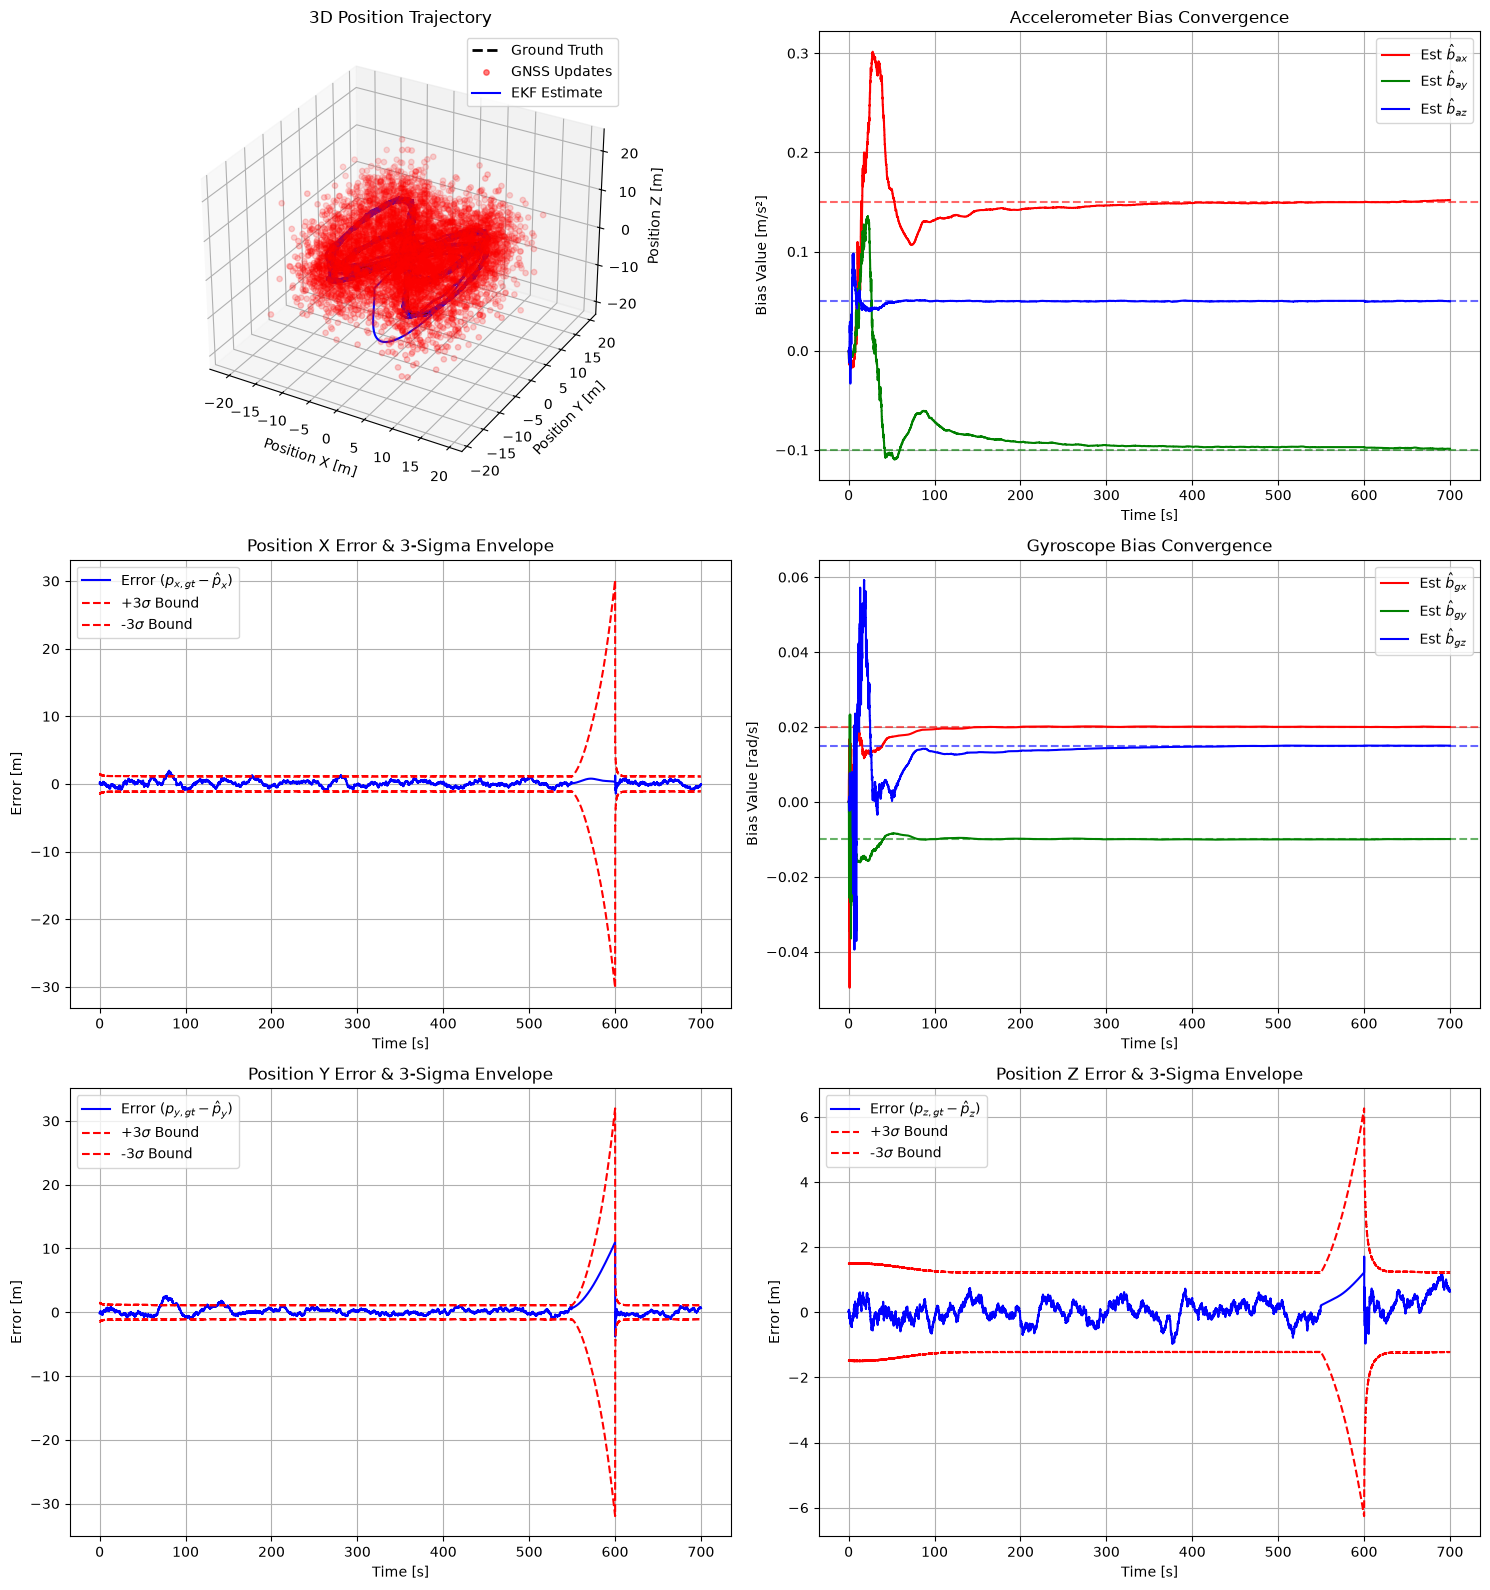

In [74]:
t, imu_data, gnss_measurements, gt_states, true_biases = generate_synthetic_data(
    duration=700,
    outage_bounds=(550,600)
)

ekf = EKF_3D()

gnss_idx = 0
ekf_states = []
P_history = []

for i in range(len(t)):
    u_k = imu_data[i]
    ekf.predict(u_k)
    
    if gnss_idx < len(gnss_measurements) and gnss_measurements[gnss_idx][0] == i:
        z_k = gnss_measurements[gnss_idx][1]
        ekf.update(z_k)
        gnss_idx += 1
        
    ekf_states.append(ekf.x.copy())
    P_history.append(ekf.P.copy())

plot_ekf_results(t, gt_states, ekf_states, P_history, gnss_measurements, true_biases)